<a href="https://colab.research.google.com/github/razokiyassine/Network-Intrusion-Detection/blob/main/TP1_K-Means.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dimensions : (300, 4)
Doublons exacts : 0


,type,valeurs_manquantes
duration_s,float64,0
bytes_sent,float64,0
packets,float64,0
failed_logins,int64,0


,duration_s,bytes_sent,packets,failed_logins
0,2.920270,913.717953,8.938569,5
1,3.131058,834.723099,10.475353,5
2,77.720468,32316.297100,417.785080,1
3,10.464521,1333.623486,33.245852,0
4,2.422106,847.643996,14.884610,6


,duration_s,bytes_sent,packets,failed_logins
count,300.00,300.00,300.00,300.00
mean,33.72,9141.30,147.11,1.99
std,38.17,11327.05,179.16,2.66
min,0.33,362.19,7.64,0.00
25%,3.39,862.37,13.27,0.00
50%,12.00,1764.98,34.47,1.00
75%,76.70,22478.99,349.92,4.00
max,114.68,34741.28,545.22,13.00


,K,inertie,silhouette
0,2,310.0663,0.7114
1,3,108.0198,0.7473
2,4,69.2488,0.7554
3,5,57.1176,0.7683
4,6,48.9048,0.5901


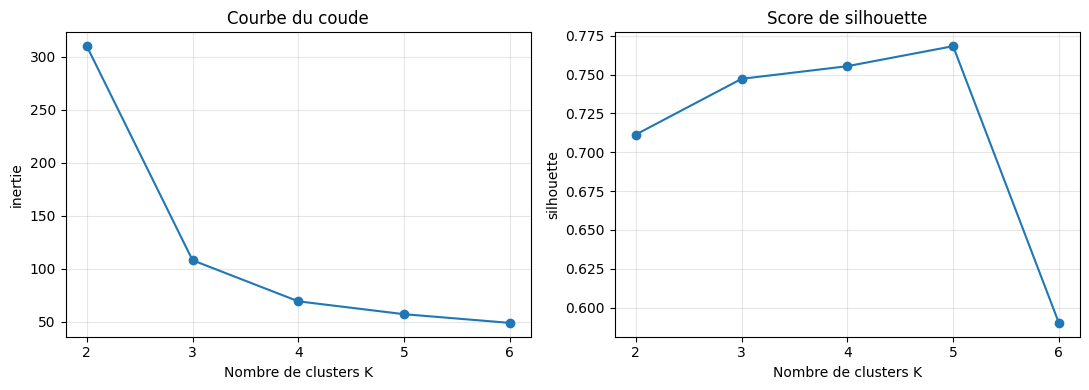

K retenu = 5, meilleure silhouette = 0.7683


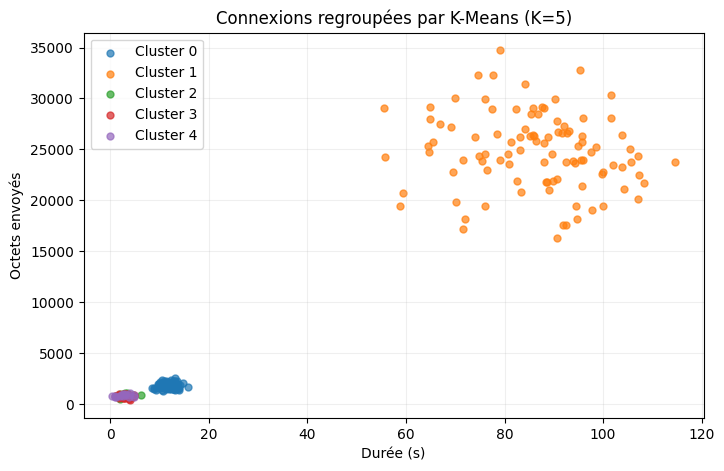

Profils avec failed_logins


,effectif,duration_s,bytes_sent,packets,failed_logins
cluster,,,,,
0,102,11.72,1778.07,34.27,0.00
1,100,86.31,24831.68,394.52,0.83
2,39,3.05,820.82,12.12,5.72
3,44,2.94,763.80,12.04,3.45
4,15,2.68,815.94,12.25,9.20


Profils sans failed_logins à l'entraînement


,effectif,duration_s,bytes_sent,packets,failed_logins
cluster,,,,,
0,200,7.42,1296.11,23.41,2.56
1,26,79.78,28435.55,443.93,0.65
2,31,97.41,22367.15,419.89,1.03
3,25,91.74,25551.75,325.69,0.64
4,18,69.06,22870.48,375.04,1.00


Silhouette avec failed_logins : 0.7683
Silhouette sans failed_logins : 0.7244
Accord entre les deux partitions (ARI) : 0.2364


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

# 1. Générer les données de l'énoncé
rng = np.random.default_rng(42)
parts = []

for n, duration, sent, packets, failed in [
    (100, 12, 1800, 35, 0),
    (100, 85, 25000, 400, 1),
    (100, 3, 800, 12, 5),
]:
    parts.append(pd.DataFrame({
        "duration_s": np.maximum(0, rng.normal(duration, max(1, duration * .15), n)),
        "bytes_sent": np.maximum(0, rng.normal(sent, sent * .15, n)),
        "packets": np.maximum(0, rng.normal(packets, max(2, packets * .15), n)),
        "failed_logins": rng.poisson(failed, n),
    }))

df = (
    pd.concat(parts, ignore_index=True)
    .sample(frac=1, random_state=42)
    .reset_index(drop=True)
)

# 2. Vérifier les données avant la standardisation
print("Dimensions :", df.shape)
print("Doublons exacts :", df.duplicated().sum())
display(pd.DataFrame({
    "type": df.dtypes.astype(str),
    "valeurs_manquantes": df.isna().sum(),
}))
display(df.head())
display(df.describe().round(2))

X_scaled = StandardScaler().fit_transform(df)

# 3. Tester K de 2 à 6
models = {}
results = []

for k in range(2, 7):
    model = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_scaled)
    models[k] = model
    results.append({
        "K": k,
        "inertie": model.inertia_,
        "silhouette": silhouette_score(X_scaled, model.labels_),
    })

scores = pd.DataFrame(results)
display(scores.round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric, title in zip(
    axes, ["inertie", "silhouette"], ["Courbe du coude", "Score de silhouette"]
):
    ax.plot(scores["K"], scores[metric], marker="o")
    ax.set(xlabel="Nombre de clusters K", ylabel=metric, title=title)
    ax.set_xticks(scores["K"])
    ax.grid(alpha=.3)
plt.tight_layout()
plt.show()

# 4. Retenir K selon la meilleure silhouette observée
best = scores.loc[scores["silhouette"].idxmax()]
k = int(best["K"])
labels = models[k].labels_

print(f"K retenu = {k}, meilleure silhouette = {best['silhouette']:.4f}")

fig, ax = plt.subplots(figsize=(8, 5))
for cluster in range(k):
    group = df.loc[labels == cluster]
    ax.scatter(group["duration_s"], group["bytes_sent"],
               s=25, alpha=.7, label=f"Cluster {cluster}")

ax.set(xlabel="Durée (s)", ylabel="Octets envoyés",
       title=f"Connexions regroupées par K-Means (K={k})")
ax.legend()
ax.grid(alpha=.2)
plt.show()

# 5. Comparer les profils moyens dans les unités d'origine
def afficher_profils(cluster_labels, titre):
    groups = df.assign(cluster=cluster_labels).groupby("cluster")
    profiles = groups.mean().round(2)
    profiles.insert(0, "effectif", groups.size())
    print(titre)
    display(profiles)

afficher_profils(labels, "Profils avec failed_logins")

# 6. Refaire K-Means au même K, sans failed_logins
X_reduit = StandardScaler().fit_transform(df.drop(columns="failed_logins"))
labels_reduits = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X_reduit)

afficher_profils(labels_reduits, "Profils sans failed_logins à l'entraînement")

print(f"Silhouette avec failed_logins : {silhouette_score(X_scaled, labels):.4f}")
print(f"Silhouette sans failed_logins : {silhouette_score(X_reduit, labels_reduits):.4f}")
print(f"Accord entre les deux partitions (ARI) : "
      f"{adjusted_rand_score(labels, labels_reduits):.4f}")